# Forecast-Driven Carbon-Aware Edge-Cloud Task Offloading
## End-to-end ML notebook for the cloud research project

**Project objective:** forecast task execution duration and regional carbon intensity, then use those predictions in a simple carbon-aware edge/cloud scheduler.

**Reference model:** `RandomForestRegressor`. The notebook now benchmarks Extra Trees, HistGradientBoosting and optional XGBoost for tabular regression, plus an optional LSTM for regional carbon time-series forecasting. Random Forest remains the scheduler's reference model so existing downstream cells remain reproducible.

### What this notebook does
1. Loads and inspects `master_dataset(1).xlsx`.
2. Cleans and prepares task-level data.
3. Trains a duration regression model and evaluates it on a chronological holdout.
4. Builds regional carbon-intensity time series and trains a one-step-ahead forecasting model with lag features.
5. Evaluates both models using MAE, RMSE and R².
6. Uses the forecasts in an illustrative edge/cloud scheduling policy.
7. Compares decisions and estimated energy/carbon under the stated assumptions.
8. Exposes a model registry and reusable `run_simulation()` function for model selection.
9. Exports a portable inference bundle for a FastAPI service used by the website.

> **Scientific honesty:** this dataset does not contain a direct server CPU-utilization label. This notebook predicts task duration and carbon intensity. Server utilization and energy are estimated using explicit assumptions, not presented as measured values. The scheduler is a research prototype, not a production deployment.

## 0. Install/import dependencies

Core models use scikit-learn. XGBoost and LSTM are optional comparisons. Install them if you want every experiment:

```python
%pip install pandas numpy scikit-learn matplotlib seaborn openpyxl joblib xgboost tensorflow fastapi uvicorn
```

TensorFlow can be large and may not support every Python version/platform. The notebook skips the LSTM experiment cleanly if TensorFlow is unavailable.

For website integration, the notebook also exports `ml_artifacts/inference_bundle.joblib`. A companion `ml_service.py` loads this bundle and exposes `/models` and `/simulate` endpoints. The website should call this API; it should not execute the notebook directly.

### Recommended execution
Run the notebook from top to bottom. Keep `master_dataset(1).xlsx` beside the notebook. For all optional experiments, install `xgboost` and `tensorflow`; otherwise the XGBoost/LSTM sections are skipped where applicable. The scheduler continues to use the original Random Forest models by default; compare benchmark results before changing the deployed model.

In [1]:
# Uncomment if required:
# %pip install pandas numpy scikit-learn matplotlib seaborn openpyxl joblib

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor

# Optional dependencies: the notebook remains usable if either package is absent.
try:
    from xgboost import XGBRegressor
    XGBOOST_AVAILABLE = True
except Exception:
    XGBOOST_AVAILABLE = False

try:
    import tensorflow as tf
    from tensorflow.keras import Sequential
    from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
    from tensorflow.keras.callbacks import EarlyStopping
    TENSORFLOW_AVAILABLE = True
except Exception:
    TENSORFLOW_AVAILABLE = False

RANDOM_STATE = 42
if TENSORFLOW_AVAILABLE:
    tf.keras.utils.set_random_seed(RANDOM_STATE)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

## 1. Load the Excel dataset

Place this notebook in the same folder as `master_dataset(1).xlsx`, or update `DATA_PATH` to the file's location.

In [2]:
DATA_PATH = Path("master_dataset(1).xlsx")

if not DATA_PATH.exists():
    # Also check the current working directory for any xlsx file as a convenience.
    candidates = list(Path.cwd().glob("*.xlsx"))
    if len(candidates) == 1:
        DATA_PATH = candidates[0]
    else:
        raise FileNotFoundError(
            "Could not find master_dataset(1).xlsx. Put the file beside this notebook "
            "or update DATA_PATH to its full path."
        )

df = pd.read_excel(DATA_PATH)
print("Dataset path:", DATA_PATH.resolve())
print("Shape:", df.shape)
display(df.head())

Dataset path: C:\Users\user\ml model gpt 2\master_dataset.xlsx
Shape: (7539, 77)


,task_id,device_id,priority,task_size_mb,cpu_demand,gpu_demand,observed_duration_sec,delay_tolerance_sec,arrival_time_trace_sec,sim_offset_sec,sim_timestamp_utc,device_region,device_city,device_city_lat,device_city_lon,local_edge_num_servers,cloud_region,carbon_intensity_local,carbon_intensity_cloud,carbon_replay_wrapped,carbon_timestamp_utc,carbon_intensity_california,carbon_intensity_desert_southwest,carbon_intensity_florida,carbon_intensity_mid_atlantic,carbon_intensity_midwest,carbon_intensity_new_england,carbon_intensity_new_york,carbon_intensity_pacific_northwest,carbon_intensity_texas,renewable_pct_california,renewable_pct_desert_southwest,renewable_pct_florida,renewable_pct_mid_atlantic,renewable_pct_midwest,renewable_pct_new_england,renewable_pct_new_york,renewable_pct_pacific_northwest,renewable_pct_texas,generation_mw_california,generation_mw_desert_southwest,generation_mw_florida,generation_mw_mid_atlantic,generation_mw_midwest,generation_mw_new_england,generation_mw_new_york,generation_mw_pacific_northwest,generation_mw_texas,device_type,device_location_x_m,device_location_y_m,transmit_power_dbm,transmit_power_basis,local_processing_rate_mhz,device_cores,battery_capacity_mah,battery_capacity_basis,radio_type,edge_num_servers,edge_cap_cpu_cores,edge_cap_mem_gb,edge_cap_gpu_cards,edge_idle_power_watts,edge_full_load_power_watts,edge_cost_per_hour_usd,edge_bandwidth_mbps,cloud_num_servers,cloud_cap_cpu_cores,cloud_cap_mem_gb,cloud_cap_gpu_cards,cloud_idle_power_watts,cloud_full_load_power_watts,cloud_cost_per_hour_usd,cloud_bandwidth_mbps,cloud_location_city,cloud_location_lat,cloud_location_lon
0,1f06979f0a3db120db7a36fe_worker,4,low,80000,2000,100,159211,238816.5,982217,0,2026-09-01 07:00:00+00:00,Mid-Atlantic,Philadelphia,39.9526,-75.1652,2,California,371.214236,377.000708,False,2026-09-01 07:00:00+00:00,377.000708,376.042719,440.267656,371.214236,480.277906,313.539573,293.280369,350.132219,363.691084,16.56,8.69,0.06,5.75,8.69,2.48,19.39,40.52,29.46,26836,16269.000000,27229.000000,108656.000000,76076.000000,11624.000000,14324.000000,40607.000000,63590.000000,ESP32-WROOM-32,22.5,15,19.5,manufacturer_datasheet_typical_80211b,240,2,2000,reference_assumption,WiFi 802.11 b/g/n,20,96,512,0,49.8,432,5.376,25000,5,96,512,8,49.8,432,5.376,25000,N. California (AWS us-west-1),37.3541,-121.9552
1,b643578285eac064d1a906cb_tensorflow,7,low,30000,600,100,56498,84747.0,1065436,83219,2026-09-02 06:06:59+00:00,New York,New York City,40.7128,-74.0060,2,California,309.538463,387.005364,False,2026-09-02 06:05:00+00:00,387.005364,370.325896,461.942753,396.449451,452.576765,305.211941,309.538463,306.055595,355.653550,15.12,11.23,0.05,4.61,15.09,6.57,16.04,48.41,30.96,27780,17461.416667,28512.666667,114918.250000,85878.000000,12368.333333,14809.750000,44898.583333,67255.083333,ESP32-WROOM-32,22.5,8,19.5,manufacturer_datasheet_typical_80211b,240,2,2000,reference_assumption,WiFi 802.11 b/g/n,20,96,512,0,49.8,432,5.376,25000,5,96,512,8,49.8,432,5.376,25000,N. California (AWS us-west-1),37.3541,-121.9552
2,671df365104fd23baecf73fd_TensorboardTask,6,low,2020,100,0,59792,89688.0,1077960,95743,2026-09-02 09:35:43+00:00,New England,Boston,42.3601,-71.0589,2,California,302.483270,357.942257,False,2026-09-02 09:35:00+00:00,357.942257,376.105727,456.933582,384.873212,440.186428,302.483270,301.859258,327.454758,372.740095,19.57,8.20,0.05,4.82,14.71,7.16,16.99,44.34,27.50,23310,15710.250000,26941.083333,109649.833333,76933.166667,12421.083333,14202.583333,39512.000000,61515.250000,Arduino Portenta H7,19.5,12,17.0,radio_module_datasheet_murata_1dx,480,2,700,manufacturer_documented_minimum,WiFi + Bluetooth (via Portenta Vision Shield /...,20,96,512,0,49.8,432,5.376,25000,5,96,512,8,49.8,432,5.376,25000,N. California (AWS us-west-1),37.3541,-121.9552
3,0bc8ee204a68846898818bae_tensorflow,6,low,30000,600,400,55116,82674.0,1087037,104820,2026-09-02 12:07:00+00:00,New England,Boston,42.3601,-71.0589,2,California,312.994050,364.236593,False,2026-09-02 12:05

In [3]:
print("Columns:", len(df.columns))
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_values": df.isna().sum(),
    "unique_values": df.nunique()
}).sort_values(["missing_values", "unique_values"], ascending=[False, True]))

print("Duplicate rows:", df.duplicated().sum())
if "task_id" in df.columns:
    print("Duplicate task IDs:", df["task_id"].duplicated().sum())

Columns: 77


,dtype,missing_values,unique_values
cloud_region,str,0,1
edge_num_servers,int64,0,1
edge_cap_cpu_cores,int64,0,1
edge_cap_mem_gb,int64,0,1
edge_cap_gpu_cards,int64,0,1
...,...,...,...
carbon_intensity_local,float64,0,6908
arrival_time_trace_sec,int64,0,7343
sim_offset_sec,int64,0,7343
sim_timestamp_utc,str,0,7343


Duplicate rows: 0
Duplicate task IDs: 0


## 2. Data quality checks and basic exploration

We keep the original task order/timestamps available for chronological splitting. We do not randomly split the rows because that can make future observations leak into training.

In [4]:
# Parse timestamps safely and sort chronologically.
for col in ["sim_timestamp_utc", "carbon_timestamp_utc"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce", utc=True)

df = df.drop_duplicates(subset=["task_id"]).copy() if "task_id" in df.columns else df.copy()
df = df.sort_values("sim_offset_sec" if "sim_offset_sec" in df.columns else "arrival_time_trace_sec").reset_index(drop=True)

numeric_summary_cols = [
    c for c in [
        "task_size_mb", "cpu_demand", "gpu_demand", "observed_duration_sec",
        "delay_tolerance_sec", "carbon_intensity_local", "carbon_intensity_cloud"
    ] if c in df.columns
]
display(df[numeric_summary_cols].describe().T)

print("Priority distribution:")
display(df["priority"].value_counts(dropna=False).to_frame("tasks") if "priority" in df.columns else "No priority column")

,count,mean,std,min,25%,50%,75%,max
task_size_mb,7539.0,27546.581377,15030.181575,500.000000,30000.000000,30000.000000,30000.000000,307200.000000
cpu_demand,7539.0,653.134899,427.179785,1.000000,600.000000,600.000000,600.000000,9000.000000
gpu_demand,7539.0,55.837910,58.147845,0.000000,10.000000,50.000000,100.000000,800.000000
observed_duration_sec,7539.0,5912.929434,20521.204716,5.000000,136.000000,598.000000,4059.000000,547771.000000
delay_tolerance_sec,7539.0,8869.394150,30781.807074,7.500000,204.000000,897.000000,6088.500000,821656.500000
carbon_intensity_local,7539.0,336.320608,84.295778,56.911586,290.133289,346.697887,394.445301,542.507306
carbon_intensity_cloud,7539.0,282.814688,119.902584,55.995456,153.865925,339.358311,381.946409,444.729254


Priority distribution:


,tasks
priority,
medium,2515
high,2513
low,2511


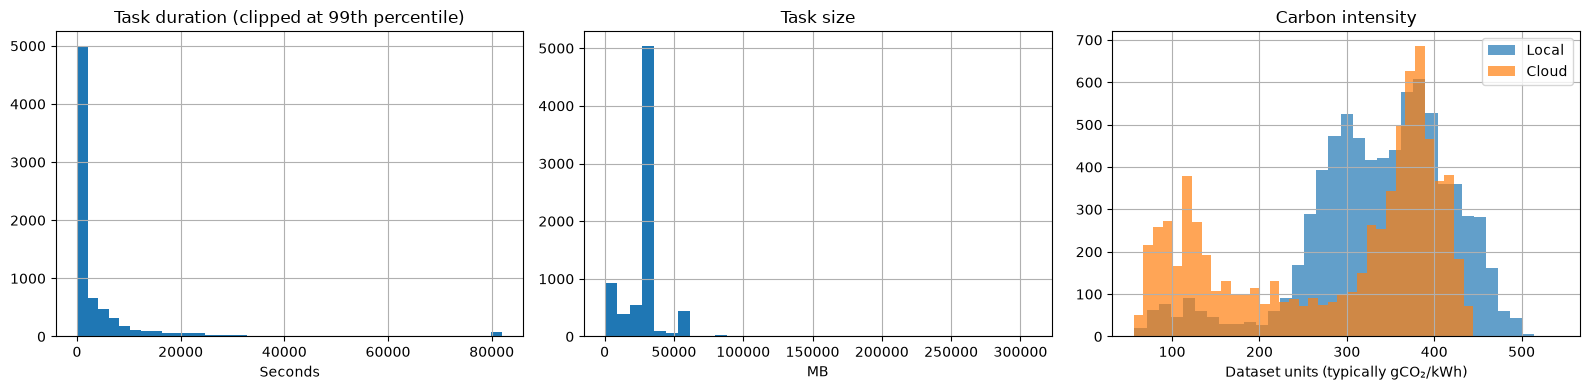

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df["observed_duration_sec"].clip(upper=df["observed_duration_sec"].quantile(0.99)).hist(bins=40, ax=axes[0])
axes[0].set_title("Task duration (clipped at 99th percentile)")
axes[0].set_xlabel("Seconds")
df["task_size_mb"].hist(bins=35, ax=axes[1])
axes[1].set_title("Task size")
axes[1].set_xlabel("MB")
df["carbon_intensity_local"].hist(bins=35, alpha=0.7, label="Local", ax=axes[2])
df["carbon_intensity_cloud"].hist(bins=35, alpha=0.7, label="Cloud", ax=axes[2])
axes[2].set_title("Carbon intensity")
axes[2].set_xlabel("Dataset units (typically gCO₂/kWh)")
axes[2].legend()
plt.tight_layout()
plt.show()

## 3. Model A — predict task execution duration

### Target
`observed_duration_sec`

### Features
Known task properties such as task size, CPU/GPU demand, priority, device type, device capacity, and region. We intentionally exclude IDs and observed outcomes that could leak the target.

We use an 80/20 **chronological split**. The first 80% trains the model; the latest 20% is held out for evaluation.

In [6]:
target_duration = "observed_duration_sec"

duration_numeric_candidates = [
    "task_size_mb", "cpu_demand", "gpu_demand", "device_id",
    "local_processing_rate_mhz", "device_cores", "battery_capacity_mah",
    "transmit_power_dbm", "device_location_x_m", "device_location_y_m",
    "delay_tolerance_sec"
]
duration_categorical_candidates = ["priority", "device_type", "device_region", "radio_type"]

duration_numeric = [c for c in duration_numeric_candidates if c in df.columns]
duration_categorical = [c for c in duration_categorical_candidates if c in df.columns]
duration_features = duration_numeric + duration_categorical

if not duration_features:
    raise ValueError("No usable duration-model features were found.")

# Keep only rows with a valid target.
duration_df = df.dropna(subset=[target_duration]).copy()
duration_df = duration_df[duration_df[target_duration] >= 0].copy()

split_idx = int(len(duration_df) * 0.80)
train_duration = duration_df.iloc[:split_idx].copy()
test_duration = duration_df.iloc[split_idx:].copy()

print("Features:", duration_features)
print("Train rows:", len(train_duration), "| Test rows:", len(test_duration))
print("Train time range:",
      train_duration["sim_timestamp_utc"].min() if "sim_timestamp_utc" in train_duration else "n/a",
      "to",
      train_duration["sim_timestamp_utc"].max() if "sim_timestamp_utc" in train_duration else "n/a")
print("Test time range:",
      test_duration["sim_timestamp_utc"].min() if "sim_timestamp_utc" in test_duration else "n/a",
      "to",
      test_duration["sim_timestamp_utc"].max() if "sim_timestamp_utc" in test_duration else "n/a")

Features: ['task_size_mb', 'cpu_demand', 'gpu_demand', 'device_id', 'local_processing_rate_mhz', 'device_cores', 'battery_capacity_mah', 'transmit_power_dbm', 'device_location_x_m', 'device_location_y_m', 'delay_tolerance_sec', 'priority', 'device_type', 'device_region', 'radio_type']
Train rows: 6031 | Test rows: 1508
Train time range: 2026-09-01 07:00:00+00:00 to 2026-09-28 01:25:59+00:00
Test time range: 2026-09-28 01:28:08+00:00 to 2026-10-03 13:45:38+00:00


In [7]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

duration_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, duration_numeric),
        ("cat", categorical_transformer, duration_categorical)
    ],
    remainder="drop"
)

duration_model = Pipeline(steps=[
    ("preprocessor", duration_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=120,
        max_depth=18,
        min_samples_leaf=2,
        max_features=0.9,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

X_train_duration = train_duration[duration_features]
y_train_duration = train_duration[target_duration]
X_test_duration = test_duration[duration_features]
y_test_duration = test_duration[target_duration]

duration_model.fit(X_train_duration, y_train_duration)
pred_duration = np.maximum(0, duration_model.predict(X_test_duration))

In [8]:
def regression_metrics(y_true, y_pred, label):
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    return {
        "model": label,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": rmse,
        "R2": r2_score(y_true, y_pred)
    }

duration_results = pd.DataFrame([
    regression_metrics(y_test_duration, pred_duration, "Random Forest"),
    regression_metrics(
        y_test_duration,
        np.repeat(y_train_duration.median(), len(y_test_duration)),
        "Median baseline"
    )
])
display(duration_results.round(3))

,model,MAE,RMSE,R2
0,Random Forest,31.528,423.114,0.999
1,Median baseline,4592.032,16810.426,-0.064


## 3A. Compare additional tabular regression algorithms (task duration)

The original Random Forest remains the reference model used by the existing scheduler. This section adds:
- **Extra Trees Regressor** — randomized tree ensemble; useful as a strong tabular baseline.
- **HistGradientBoostingRegressor** — efficient histogram-based boosting.
- **XGBoost Regressor** — regularized gradient boosting, when `xgboost` is installed.

All models use the same chronological train/test split and features. The test set is for reporting only; do not repeatedly tune models against it. The LSTM experiment is reserved for sequential carbon forecasting because task rows are not automatically a regular time series.

In [ ]:
# Build a dense one-hot preprocessor for algorithms that require dense arrays.
def make_dense_preprocessor(numeric_cols, categorical_cols):
    try:
        ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:  # scikit-learn < 1.2
        ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)

    return ColumnTransformer(
        transformers=[
            ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), numeric_cols),
            ("cat", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", ohe)
            ]), categorical_cols)
        ],
        remainder="drop"
    )

duration_dense_preprocessor = make_dense_preprocessor(duration_numeric, duration_categorical)

duration_benchmark_models = {
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=250, min_samples_leaf=2, max_features=0.9,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=250, learning_rate=0.06, max_leaf_nodes=31,
        l2_regularization=1.0, random_state=RANDOM_STATE
    )
}
if XGBOOST_AVAILABLE:
    duration_benchmark_models["XGBoost"] = XGBRegressor(
        n_estimators=350, max_depth=6, learning_rate=0.04,
        subsample=0.85, colsample_bytree=0.85, reg_lambda=2.0,
        objective="reg:squarederror", random_state=RANDOM_STATE,
        n_jobs=-1
    )

duration_benchmark_fitted = {}
duration_benchmark_rows = [regression_metrics(y_test_duration, pred_duration, "Random Forest (reference)")]
for model_name, estimator in duration_benchmark_models.items():
    candidate = Pipeline([
        ("preprocessor", duration_dense_preprocessor),
        ("model", estimator)
    ])
    candidate.fit(X_train_duration, y_train_duration)
    candidate_pred = np.maximum(0, candidate.predict(X_test_duration))
    duration_benchmark_fitted[model_name] = candidate
    duration_benchmark_rows.append(regression_metrics(y_test_duration, candidate_pred, model_name))

duration_comparison = pd.DataFrame(duration_benchmark_rows).sort_values("MAE")
display(duration_comparison.round(4))
print("XGBoost available:", XGBOOST_AVAILABLE)


# Canonical registry entry for the reference model.
duration_benchmark_fitted["Random Forest"] = duration_model


,task_id,observed_duration_sec,predicted_duration_sec,absolute_error_sec
6031,bc82810978fbabb532700746_ps,44,44.016667,0.016667
6032,bc82810978fbabb532700746_worker,30,30.000000,0.000000
6033,4469c7ea017f167239c58f53_ps,53,52.986667,0.013333
6034,4469c7ea017f167239c58f53_worker,30,30.039881,0.039881
6035,0aa27d66d5d68cee31d8b8d1_tensorflow,28,27.980833,0.019167
6036,6c28e7151e2575718eb515d4_PyTorchWorker,840,841.098419,1.098419
6037,fa16e7278d6975234eee68c5_PyTorchWorker,815,816.503092,1.503092
6038,260c26070f82470ec3bd4942_PyTorchWorker,217,216.597996,0.402004
6039,69dcbd2aa6a6975731abe966_PyTorchWorker,1201,1199.000837,1.999163
6040,b471410e74b1434a950218bd_ps,35,35.013889,0.013889


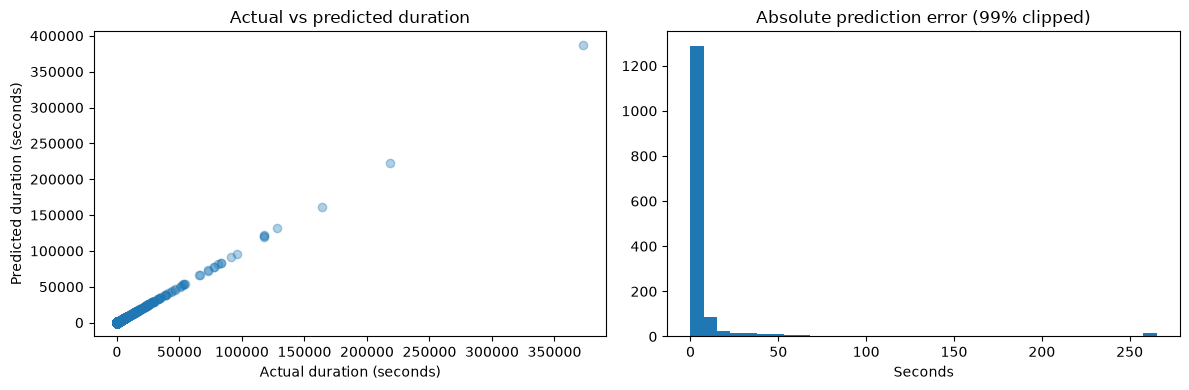

In [9]:
duration_predictions = test_duration[["task_id", "observed_duration_sec"]].copy()
duration_predictions["predicted_duration_sec"] = pred_duration
duration_predictions["absolute_error_sec"] = (
    duration_predictions["observed_duration_sec"] - duration_predictions["predicted_duration_sec"]
).abs()
display(duration_predictions.head(10))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_test_duration, pred_duration, alpha=0.35)
axes[0].set_xlabel("Actual duration (seconds)")
axes[0].set_ylabel("Predicted duration (seconds)")
axes[0].set_title("Actual vs predicted duration")
axes[1].hist(duration_predictions["absolute_error_sec"].clip(
    upper=duration_predictions["absolute_error_sec"].quantile(0.99)), bins=35)
axes[1].set_title("Absolute prediction error (99% clipped)")
axes[1].set_xlabel("Seconds")
plt.tight_layout()
plt.show()

## 4. Model B — forecast regional carbon intensity one time step ahead

The workbook includes carbon-intensity columns for several regions. We turn these into a long time series, one row per timestamp and region, then construct lag features from **past values only**.

- Target: next observed carbon intensity for a region.
- Features: region, hour/day features, and lagged carbon intensity values.
- Split: chronological, by timestamp.
- Important: this is a one-step-ahead forecast at the dataset's observed time resolution. It should not be described as a multi-hour forecast without additional recursive forecasting and evaluation.

In [10]:
regions = [
    "california", "desert_southwest", "florida", "mid_atlantic",
    "midwest", "new_england", "new_york", "pacific_northwest", "texas"
]
carbon_columns = [f"carbon_intensity_{r}" for r in regions if f"carbon_intensity_{r}" in df.columns]
if "carbon_timestamp_utc" not in df.columns or not carbon_columns:
    raise ValueError("Carbon forecast requires carbon_timestamp_utc and regional carbon-intensity columns.")

# Duplicate task rows can share a carbon timestamp. Average duplicates at timestamp-region level.
carbon_wide = (
    df.dropna(subset=["carbon_timestamp_utc"])
      .groupby("carbon_timestamp_utc", as_index=False)[carbon_columns]
      .mean()
      .sort_values("carbon_timestamp_utc")
      .reset_index(drop=True)
)
carbon_long = carbon_wide.melt(
    id_vars=["carbon_timestamp_utc"],
    value_vars=carbon_columns,
    var_name="region",
    value_name="carbon_intensity"
)
carbon_long["region"] = carbon_long["region"].str.replace("carbon_intensity_", "", regex=False)
carbon_long = carbon_long.sort_values(["region", "carbon_timestamp_utc"]).reset_index(drop=True)

# Features use only prior observations for the same region.
for lag in [1, 2, 3, 6]:
    carbon_long[f"lag_{lag}"] = carbon_long.groupby("region")["carbon_intensity"].shift(lag)

carbon_long["rolling_mean_3"] = carbon_long.groupby("region")["carbon_intensity"].transform(
    lambda s: s.shift(1).rolling(3, min_periods=3).mean()
)
carbon_long["rolling_std_3"] = carbon_long.groupby("region")["carbon_intensity"].transform(
    lambda s: s.shift(1).rolling(3, min_periods=3).std()
)
carbon_long["hour"] = carbon_long["carbon_timestamp_utc"].dt.hour
carbon_long["day_of_week"] = carbon_long["carbon_timestamp_utc"].dt.dayofweek
carbon_long["month"] = carbon_long["carbon_timestamp_utc"].dt.month
carbon_long["target_next_carbon"] = carbon_long.groupby("region")["carbon_intensity"].shift(-1)
carbon_long["target_timestamp"] = carbon_long.groupby("region")["carbon_timestamp_utc"].shift(-1)

carbon_features_num = ["lag_1", "lag_2", "lag_3", "lag_6", "rolling_mean_3", "rolling_std_3",
                       "hour", "day_of_week", "month"]
carbon_features_cat = ["region"]
carbon_features = carbon_features_num + carbon_features_cat

carbon_model_df = carbon_long.dropna(subset=carbon_features_num + ["target_next_carbon", "target_timestamp"]).copy()
unique_target_times = np.sort(carbon_model_df["target_timestamp"].unique())
carbon_cutoff = unique_target_times[int(len(unique_target_times) * 0.80)]

train_carbon = carbon_model_df[carbon_model_df["target_timestamp"] <= carbon_cutoff].copy()
test_carbon = carbon_model_df[carbon_model_df["target_timestamp"] > carbon_cutoff].copy()

print("Regional carbon series shape:", carbon_long.shape)
print("Usable supervised rows:", len(carbon_model_df))
print("Train rows:", len(train_carbon), "| Test rows:", len(test_carbon))
print("Chronological cutoff:", carbon_cutoff)

Regional carbon series shape: (37233, 14)
Usable supervised rows: 37170
Train rows: 29745 | Test rows: 7425
Chronological cutoff: 2026-09-25 06:25:00+00:00


In [11]:
carbon_preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), carbon_features_num),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), carbon_features_cat)
    ],
    remainder="drop"
)

carbon_model = Pipeline(steps=[
    ("preprocessor", carbon_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=120,
        max_depth=18,
        min_samples_leaf=2,
        max_features=0.9,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

carbon_model.fit(train_carbon[carbon_features], train_carbon["target_next_carbon"])
pred_carbon = carbon_model.predict(test_carbon[carbon_features])

carbon_results = pd.DataFrame([
    regression_metrics(test_carbon["target_next_carbon"], pred_carbon, "Random Forest"),
    regression_metrics(
        test_carbon["target_next_carbon"],
        test_carbon["lag_1"],
        "Last-value baseline"
    )
])
display(carbon_results.round(3))

,model,MAE,RMSE,R2
0,Random Forest,2.563,5.169,0.995
1,Last-value baseline,3.702,7.676,0.989


## 4A. Compare tree-based carbon forecasting models

Compare Random Forest with Extra Trees, HistGradientBoosting and (if installed) XGBoost on the exact same chronological one-step-ahead holdout. The target is the next recorded carbon-intensity observation for each region. These are tabular lag-feature forecasters; they are not multi-step forecasts.

In [ ]:
carbon_dense_preprocessor = make_dense_preprocessor(carbon_features_num, carbon_features_cat)

carbon_benchmark_models = {
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=250, min_samples_leaf=2, max_features=0.9,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=250, learning_rate=0.05, max_leaf_nodes=31,
        l2_regularization=1.0, random_state=RANDOM_STATE
    )
}
if XGBOOST_AVAILABLE:
    carbon_benchmark_models["XGBoost"] = XGBRegressor(
        n_estimators=400, max_depth=5, learning_rate=0.035,
        subsample=0.85, colsample_bytree=0.9, reg_lambda=2.0,
        objective="reg:squarederror", random_state=RANDOM_STATE,
        n_jobs=-1
    )

carbon_benchmark_fitted = {}
carbon_benchmark_rows = [regression_metrics(
    test_carbon["target_next_carbon"], pred_carbon, "Random Forest (reference)"
)]
for model_name, estimator in carbon_benchmark_models.items():
    candidate = Pipeline([
        ("preprocessor", carbon_dense_preprocessor),
        ("model", estimator)
    ])
    candidate.fit(train_carbon[carbon_features], train_carbon["target_next_carbon"])
    candidate_pred = np.maximum(0, candidate.predict(test_carbon[carbon_features]))
    carbon_benchmark_fitted[model_name] = candidate
    carbon_benchmark_rows.append(regression_metrics(
        test_carbon["target_next_carbon"], candidate_pred, model_name
    ))

carbon_tree_comparison = pd.DataFrame(carbon_benchmark_rows).sort_values("MAE")
display(carbon_tree_comparison.round(4))


# Canonical registry entry for the reference model.
carbon_benchmark_fitted["Random Forest"] = carbon_model


## 4B. LSTM sequence model for carbon-intensity forecasting

An LSTM is appropriate here because each region has an ordered carbon-intensity time series. We create fixed-length windows independently per region, then pool the windows for training. The chronological cutoff is respected: training targets are at or before the existing cutoff, and test targets are after it.

The window length is 12 observations (not necessarily 12 hours). Interpret it using the actual timestamp interval in the dataset. TensorFlow is optional; if unavailable, this section is skipped. LSTM is not used for task-duration prediction because those task records are tabular and irregularly arriving.

In [ ]:
LSTM_WINDOW = 12
lstm_model = None
lstm_carbon_comparison = pd.DataFrame()

if not TENSORFLOW_AVAILABLE:
    print("TensorFlow is not installed; skipping LSTM. Install tensorflow and rerun this cell.")
else:
    # Build windows from each region's original ordered series.
    X_seq_train, y_seq_train, X_seq_test, y_seq_test = [], [], [], []
    seq_scalers = {}

    for region_name, group in carbon_long.groupby("region"):
        group = group.sort_values("carbon_timestamp_utc").dropna(subset=["carbon_intensity"]).copy()
        values = group["carbon_intensity"].to_numpy(dtype="float32").reshape(-1, 1)
        if len(values) <= LSTM_WINDOW + 2:
            continue

        scaler = StandardScaler()
        # Fit scaling only on observations available by the training cutoff.
        train_observed_mask = group["carbon_timestamp_utc"] <= carbon_cutoff
        if train_observed_mask.sum() < LSTM_WINDOW + 2:
            continue
        scaler.fit(values[train_observed_mask.to_numpy()])
        scaled = scaler.transform(values).astype("float32")
        seq_scalers[region_name] = scaler

        timestamps = group["carbon_timestamp_utc"].to_numpy()
        for end_idx in range(LSTM_WINDOW, len(scaled)):
            target_time = pd.Timestamp(timestamps[end_idx])
            x_window = scaled[end_idx-LSTM_WINDOW:end_idx]
            y_value = scaled[end_idx, 0]
            if target_time <= pd.Timestamp(carbon_cutoff):
                X_seq_train.append(x_window)
                y_seq_train.append(y_value)
            else:
                X_seq_test.append(x_window)
                y_seq_test.append(y_value)

    if len(X_seq_train) == 0 or len(X_seq_test) == 0:
        print("Not enough chronological sequence windows for LSTM; skipped.")
    else:
        X_seq_train = np.asarray(X_seq_train, dtype="float32")
        y_seq_train = np.asarray(y_seq_train, dtype="float32")
        X_seq_test = np.asarray(X_seq_test, dtype="float32")
        y_seq_test = np.asarray(y_seq_test, dtype="float32")

        lstm_model = Sequential([
            Input(shape=(LSTM_WINDOW, 1)),
            LSTM(48, return_sequences=True),
            Dropout(0.15),
            LSTM(24),
            Dense(16, activation="relu"),
            Dense(1)
        ])
        lstm_model.compile(optimizer="adam", loss="mse", metrics=["mae"])
        early_stop = EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
        history = lstm_model.fit(
            X_seq_train, y_seq_train,
            validation_split=0.15, epochs=60, batch_size=32,
            callbacks=[early_stop], verbose=1, shuffle=False
        )

        # Inverse-transform each regional prediction using that region's scaler.
        # Test windows are pooled, so rebuild aligned region labels in the same order.
        test_region_labels = []
        for region_name, group in carbon_long.groupby("region"):
            group = group.sort_values("carbon_timestamp_utc").dropna(subset=["carbon_intensity"])
            timestamps = group["carbon_timestamp_utc"].to_numpy()
            train_observed_mask = group["carbon_timestamp_utc"] <= carbon_cutoff
            if region_name not in seq_scalers or train_observed_mask.sum() < LSTM_WINDOW + 2:
                continue
            for end_idx in range(LSTM_WINDOW, len(timestamps)):
                if pd.Timestamp(timestamps[end_idx]) > pd.Timestamp(carbon_cutoff):
                    test_region_labels.append(region_name)

        lstm_scaled_pred = lstm_model.predict(X_seq_test, verbose=0).reshape(-1)
        lstm_actual, lstm_pred = [], []
        for idx, region_name in enumerate(test_region_labels[:len(lstm_scaled_pred)]):
            scaler = seq_scalers[region_name]
            lstm_actual.append(float(scaler.inverse_transform([[y_seq_test[idx]]])[0, 0]))
            lstm_pred.append(float(scaler.inverse_transform([[lstm_scaled_pred[idx]]])[0, 0]))

        lstm_carbon_comparison = pd.DataFrame([
            regression_metrics(lstm_actual, np.maximum(0, lstm_pred), "LSTM")
        ])
        display(lstm_carbon_comparison.round(4))
        pd.DataFrame(history.history)[["loss", "val_loss"]].plot(figsize=(8, 3), title="LSTM training loss")
        plt.tight_layout()
        plt.show()


,target_timestamp,region,target_next_carbon,lag_1,predicted_next_carbon,absolute_error
3311,2026-09-25 06:30:00+00:00,california,381.540305,382.146916,377.059889,4.480416
3312,2026-09-25 06:35:00+00:00,california,381.463879,381.850084,378.665195,2.798684
3313,2026-09-25 07:05:00+00:00,california,382.640266,381.540305,381.718855,0.921410
3314,2026-09-25 07:10:00+00:00,california,382.218862,381.463879,380.358651,1.860211
3315,2026-09-25 07:15:00+00:00,california,382.109156,382.640266,383.307136,1.197980
3316,2026-09-25 07:20:00+00:00,california,381.502921,382.218862,379.898177,1.604743
3317,2026-09-25 07:25:00+00:00,california,380.287741,382.109156,380.220093,0.067648
3318,2026-09-25 07:30:00+00:00,california,378.612439,381.502921,379.852559,1.240119
3319,2026-09-25 07:35:00+00:00,california,377.086038,380.287741,375.570290,1.515748
3320,2026-09-25 07:50:00+00:00,california,370.704388,378.612439,376.322936,5.618548


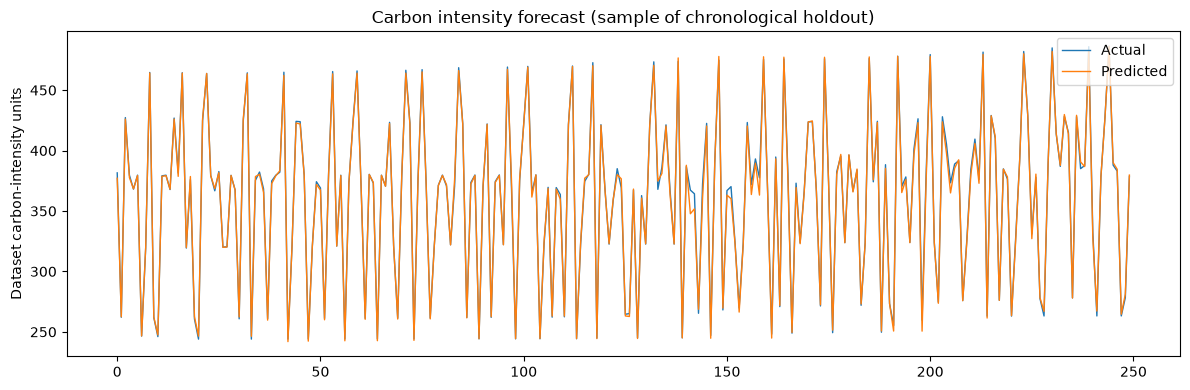

In [12]:
carbon_predictions = test_carbon[["target_timestamp", "region", "target_next_carbon", "lag_1"]].copy()
carbon_predictions["predicted_next_carbon"] = pred_carbon
carbon_predictions["absolute_error"] = (
    carbon_predictions["target_next_carbon"] - carbon_predictions["predicted_next_carbon"]
).abs()
display(carbon_predictions.head(12))

fig, ax = plt.subplots(figsize=(12, 4))
sample = carbon_predictions.sort_values("target_timestamp").head(250)
ax.plot(sample["target_next_carbon"].to_numpy(), label="Actual", linewidth=1)
ax.plot(sample["predicted_next_carbon"].to_numpy(), label="Predicted", linewidth=1)
ax.set_title("Carbon intensity forecast (sample of chronological holdout)")
ax.set_ylabel("Dataset carbon-intensity units")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Build a one-step-ahead carbon forecast lookup

For a given region, we use the latest observed lag values to predict its next carbon-intensity value. If a region has too little history or the model cannot generate a forecast, we fall back to its latest observation.

This function is for a reproducible demonstration; a real simulation should update the history as simulated time advances.

In [13]:
def forecast_next_carbon_for_region(region_name, carbon_long_df=carbon_long, model=carbon_model):
    region_name = str(region_name).lower().replace(" ", "_")
    hist = carbon_long_df[carbon_long_df["region"] == region_name].sort_values("carbon_timestamp_utc")
    if hist.empty:
        return np.nan

    latest = hist.iloc[-1]
    # Need the same lag logic as training. Use the original carbon series and recompute features.
    vals = hist["carbon_intensity"].dropna().to_numpy()
    if len(vals) < 7:
        return float(vals[-1])

    ts = hist["carbon_timestamp_utc"].iloc[-1] + (hist["carbon_timestamp_utc"].diff().dropna().median())
    if pd.isna(ts):
        ts = hist["carbon_timestamp_utc"].iloc[-1]

    row = {
        "region": region_name,
        "lag_1": vals[-1],
        "lag_2": vals[-2],
        "lag_3": vals[-3],
        "lag_6": vals[-6],
        "rolling_mean_3": np.mean(vals[-3:]),
        "rolling_std_3": np.std(vals[-3:], ddof=1),
        "hour": ts.hour,
        "day_of_week": ts.dayofweek,
        "month": ts.month
    }
    X_next = pd.DataFrame([row])[carbon_features]
    return float(max(0, model.predict(X_next)[0]))

latest_carbon_by_region = (
    carbon_long.sort_values("carbon_timestamp_utc")
    .groupby("region", as_index=False)
    .tail(1)
    .set_index("region")["carbon_intensity"]
    .to_dict()
)

carbon_forecast_lookup = {}
for region_name in sorted(carbon_long["region"].unique()):
    carbon_forecast_lookup[region_name] = forecast_next_carbon_for_region(region_name)

display(pd.DataFrame({
    "region": list(carbon_forecast_lookup.keys()),
    "latest_observed_carbon": [latest_carbon_by_region.get(r, np.nan) for r in carbon_forecast_lookup],
    "forecast_next_carbon": list(carbon_forecast_lookup.values())
}).sort_values("forecast_next_carbon"))

,region,latest_observed_carbon,forecast_next_carbon
0,california,166.963850,178.334587
1,desert_southwest,232.669594,233.384675
7,pacific_northwest,270.217835,269.740222
6,new_york,292.892677,294.338820
8,texas,293.184718,299.757666
5,new_england,343.214919,344.692913
3,mid_atlantic,373.995912,378.585308
2,florida,434.020182,440.927772
4,midwest,463.798096,466.551618


## 5A. Selectable model registry and reusable simulation function

This section is the integration boundary for the website.

- `random_forest`: Random Forest for duration and carbon forecasting.
- `xgboost`: XGBoost for both tasks (requires the optional package).
- `hist_gradient_boosting`: HistGradientBoosting for both tasks.
- `lstm`: LSTM for carbon forecasting; task duration intentionally remains on the Random Forest duration model because this notebook does not train an LSTM task-duration model.

`run_simulation(model_name, ...)` is the common function a Python API can call. It returns JSON-serializable summary metrics and per-task decisions. It uses the same held-out tasks by default for reproducible comparisons; pass a DataFrame of task records for another trace. Carbon forecasts are selected by model and recomputed from each region's latest available history.

Important: this is still a one-step forecast and a prototype scheduler. The energy/carbon values are estimates under the assumptions documented above, not measured hardware values.

In [ ]:
def normalize_region_name(value):
    return str(value).strip().lower().replace(' ', '_')

# Registry is populated only with models that were successfully trained.
DURATION_MODEL_REGISTRY = {
    "random_forest": duration_model,
}
CARBON_MODEL_REGISTRY = {
    "random_forest": carbon_model,
}

if "XGBoost" in duration_benchmark_fitted:
    DURATION_MODEL_REGISTRY["xgboost"] = duration_benchmark_fitted["XGBoost"]
if "XGBoost" in carbon_benchmark_fitted:
    CARBON_MODEL_REGISTRY["xgboost"] = carbon_benchmark_fitted["XGBoost"]

if "HistGradientBoosting" in duration_benchmark_fitted:
    DURATION_MODEL_REGISTRY["hist_gradient_boosting"] = duration_benchmark_fitted["HistGradientBoosting"]
if "HistGradientBoosting" in carbon_benchmark_fitted:
    CARBON_MODEL_REGISTRY["hist_gradient_boosting"] = carbon_benchmark_fitted["HistGradientBoosting"]

# LSTM predicts carbon intensity only. Duration remains Random Forest for this option.
if lstm_model is not None and TENSORFLOW_AVAILABLE:
    CARBON_MODEL_REGISTRY["lstm"] = lstm_model

MODEL_OPTIONS = [
    {"id": "random_forest", "label": "Random Forest",
     "duration_model": "Random Forest", "carbon_model": "Random Forest"},
]
if "xgboost" in CARBON_MODEL_REGISTRY and "xgboost" in DURATION_MODEL_REGISTRY:
    MODEL_OPTIONS.append({"id": "xgboost", "label": "XGBoost",
                          "duration_model": "XGBoost", "carbon_model": "XGBoost"})
if "hist_gradient_boosting" in CARBON_MODEL_REGISTRY and "hist_gradient_boosting" in DURATION_MODEL_REGISTRY:
    MODEL_OPTIONS.append({"id": "hist_gradient_boosting", "label": "HistGradientBoosting",
                          "duration_model": "HistGradientBoosting", "carbon_model": "HistGradientBoosting"})
if "lstm" in CARBON_MODEL_REGISTRY:
    MODEL_OPTIONS.append({"id": "lstm", "label": "LSTM",
                          "duration_model": "Random Forest (fixed)", "carbon_model": "LSTM"})

def _forecast_carbon_selectable(region_name, model_name, history_df=None):
    """Forecast the next carbon value for one region using the selected model."""
    region_name = str(region_name).strip().lower().replace(" ", "_")
    history_df = carbon_long if history_df is None else history_df
    hist = history_df[history_df["region"] == region_name].sort_values("carbon_timestamp_utc")
    vals = hist["carbon_intensity"].dropna().to_numpy(dtype=float)
    if len(vals) == 0:
        return np.nan
    if len(vals) < 7:
        return float(vals[-1])

    if model_name == "lstm":
        if lstm_model is None or region_name not in seq_scalers or len(vals) < LSTM_WINDOW:
            return float(vals[-1])
        scaler = seq_scalers[region_name]
        x = scaler.transform(vals[-LSTM_WINDOW:].reshape(-1, 1)).astype("float32")
        pred_scaled = float(lstm_model.predict(x.reshape(1, LSTM_WINDOW, 1), verbose=0)[0, 0])
        return float(max(0.0, scaler.inverse_transform([[pred_scaled]])[0, 0]))

    model = CARBON_MODEL_REGISTRY.get(model_name)
    if model is None:
        raise ValueError(f"Carbon model '{model_name}' is unavailable. Available: {list(CARBON_MODEL_REGISTRY)}")

    delta = hist["carbon_timestamp_utc"].diff().dropna().median()
    next_ts = hist["carbon_timestamp_utc"].iloc[-1] + delta
    if pd.isna(next_ts):
        next_ts = hist["carbon_timestamp_utc"].iloc[-1]
    row = {
        "region": region_name,
        "lag_1": vals[-1], "lag_2": vals[-2], "lag_3": vals[-3], "lag_6": vals[-6],
        "rolling_mean_3": float(np.mean(vals[-3:])),
        "rolling_std_3": float(np.std(vals[-3:], ddof=1)),
        "hour": int(next_ts.hour), "day_of_week": int(next_ts.dayofweek), "month": int(next_ts.month)
    }
    return float(max(0.0, model.predict(pd.DataFrame([row])[carbon_features])[0]))

def _selected_duration_predict(task_frame, model_name):
    # LSTM is carbon-only in this study; RF duration remains fixed for the LSTM option.
    duration_key = "random_forest" if model_name == "lstm" else model_name
    model = DURATION_MODEL_REGISTRY.get(duration_key)
    if model is None:
        raise ValueError(f"Duration model for '{model_name}' is unavailable. Available: {list(DURATION_MODEL_REGISTRY)}")
    X = task_frame.reindex(columns=duration_features)
    return np.maximum(0.0, model.predict(X))

def run_simulation(model_name="random_forest", tasks=None, policy="proposed_weighted", max_tasks=500):
    """
    Run the carbon-aware scheduler with a user-selected ML model.

    Parameters
    ----------
    model_name : random_forest | xgboost | hist_gradient_boosting | lstm
    tasks : optional pandas DataFrame of task records. If omitted, uses held-out test tasks.
    policy : proposed_weighted | edge_first | lowest_carbon | lowest_energy
    max_tasks : maximum number of task rows to process

    Returns
    -------
    dict : JSON-serializable model metadata, aggregate metrics and task decisions.
    """
    if model_name not in CARBON_MODEL_REGISTRY:
        raise ValueError(f"Model '{model_name}' unavailable. Choose from: {list(CARBON_MODEL_REGISTRY)}")
    if policy not in {"proposed_weighted", "edge_first", "lowest_carbon", "lowest_energy"}:
        raise ValueError("Unknown policy. Use proposed_weighted, edge_first, lowest_carbon or lowest_energy.")

    task_frame = (test_duration.copy() if tasks is None else tasks.copy()).head(int(max_tasks)).reset_index(drop=True)
    if task_frame.empty:
        raise ValueError("No task rows supplied to the simulation.")

    predicted_durations = _selected_duration_predict(task_frame, model_name)
    rows = []
    for idx, (_, task) in enumerate(task_frame.iterrows()):
        local_region = normalize_region_name(task.get("device_region", ""))
        cloud_region = normalize_region_name(task.get("cloud_region", "california"))
        local_carbon = _forecast_carbon_selectable(local_region, model_name)
        cloud_carbon = _forecast_carbon_selectable(cloud_region, model_name)

        if pd.isna(local_carbon):
            local_carbon = _safe_task_number(task.get("carbon_intensity_local", 350.0), 350.0)
        if pd.isna(cloud_carbon):
            cloud_carbon = _safe_task_number(task.get("carbon_intensity_cloud", 350.0), 350.0)

        def _safe_task_number(value, default):
            try:
                return float(default) if value is None or pd.isna(value) else float(value)
            except (TypeError, ValueError):
                return float(default)

        deadline = _safe_task_number(task.get("delay_tolerance_sec", np.inf), np.inf)
        cpu = _safe_task_number(task.get("cpu_demand", 0), 0.0)
        gpu = _safe_task_number(task.get("gpu_demand", 0), 0.0)
        feasible = {}
        if gpu <= 0 or EDGE_GPU_CARDS > 0:
            p = estimate_power_watts(cpu, EDGE_IDLE_W, EDGE_FULL_W)
            feasible["edge"] = score_candidate(predicted_durations[idx], p, local_carbon, deadline)
        if gpu <= 0 or CLOUD_GPU_CARDS > 0:
            p = estimate_power_watts(cpu, CLOUD_IDLE_W, CLOUD_FULL_W)
            feasible["cloud"] = score_candidate(predicted_durations[idx], p, cloud_carbon, deadline)

        if not feasible:
            placement = "no_feasible_candidate"
            chosen_metrics = {}
        elif policy == "edge_first":
            placement = "edge" if "edge" in feasible else "cloud"
            chosen_metrics = feasible[placement]
        elif policy == "lowest_carbon":
            placement = min(feasible, key=lambda k: feasible[k]["estimated_co2_g"])
            chosen_metrics = feasible[placement]
        elif policy == "lowest_energy":
            placement = min(feasible, key=lambda k: feasible[k]["energy_kwh"])
            chosen_metrics = feasible[placement]
        else:
            placement = min(feasible, key=lambda k: feasible[k]["score"])
            chosen_metrics = feasible[placement]

        rows.append({
            "task_id": str(task.get("task_id", idx)),
            "priority": str(task.get("priority", "")),
            "placement": placement,
            "predicted_duration_sec": float(predicted_durations[idx]),
            "deadline_sec": None if not np.isfinite(deadline) else deadline,
            "local_carbon_forecast": float(local_carbon),
            "cloud_carbon_forecast": float(cloud_carbon),
            "estimated_energy_kwh": float(chosen_metrics.get("energy_kwh", 0.0)),
            "estimated_co2_g": float(chosen_metrics.get("estimated_co2_g", 0.0)),
            "deadline_miss_predicted": bool(chosen_metrics.get("deadline_miss", False)),
            "scheduler_score": float(chosen_metrics.get("score", 0.0))
        })

    decisions = pd.DataFrame(rows)
    valid = decisions[decisions["placement"].isin(["edge", "cloud"])]
    summary = {
        "model": model_name,
        "duration_model": "random_forest" if model_name == "lstm" else model_name,
        "carbon_model": model_name,
        "policy": policy,
        "tasks_submitted": int(len(decisions)),
        "tasks_scheduled": int(len(valid)),
        "placement_counts": decisions["placement"].value_counts().to_dict(),
        "total_estimated_energy_kwh": float(valid["estimated_energy_kwh"].sum()),
        "total_estimated_co2_g": float(valid["estimated_co2_g"].sum()),
        "predicted_deadline_miss_rate": float(valid["deadline_miss_predicted"].mean()) if len(valid) else None,
        "mean_predicted_duration_sec": float(valid["predicted_duration_sec"].mean()) if len(valid) else None,
        "decisions": decisions.to_dict(orient="records")
    }
    return summary

print("Website-selectable model options:")
display(pd.DataFrame(MODEL_OPTIONS))


## 6. Carbon-aware edge/cloud scheduler prototype

The scheduler scores feasible placements using:
- predicted task duration,
- estimated energy,
- estimated carbon emissions,
- deadline feasibility,
- GPU feasibility.

### Explicit assumptions (replace with measured/simulator values later)
1. `cpu_demand` is treated as a relative workload indicator, not a measured utilization percentage.
2. Approximate utilization proxy = `cpu_demand / max(cpu_demand in training data)`, clipped to 0–1.
3. Power is linearly interpolated between idle and full-load power:  
   `P(u) = P_idle + (P_full - P_idle) × u`
4. Energy in kWh = `power_W × duration_sec / 3,600,000`.
5. CO₂ in grams = `energy_kWh × carbon_intensity_g_per_kWh`.
6. Because measured network latency is not supplied, this prototype uses task duration as its execution-time estimate and does not claim to model network latency accurately.
7. The workbook states zero edge GPU cards and eight cloud GPU cards. Tasks with positive GPU demand are therefore treated as cloud-only in this prototype.
8. Carbon-aware scoring weights below are tunable research parameters, not learned parameters.

In [14]:
# These constants come from the workbook's infrastructure columns.
example = df.iloc[0]
EDGE_IDLE_W = float(df["edge_idle_power_watts"].median())
EDGE_FULL_W = float(df["edge_full_load_power_watts"].median())
CLOUD_IDLE_W = float(df["cloud_idle_power_watts"].median())
CLOUD_FULL_W = float(df["cloud_full_load_power_watts"].median())

EDGE_GPU_CARDS = int(df["edge_cap_gpu_cards"].median())
CLOUD_GPU_CARDS = int(df["cloud_cap_gpu_cards"].median())
CPU_DEMAND_SCALE = max(float(train_duration["cpu_demand"].max()), 1.0)

# Scheduler weights: increase carbon weight to favor lower emissions;
# increase deadline weight to penalize placements likely to miss deadlines.
WEIGHT_CARBON = 0.55
WEIGHT_LATENCY = 0.25
WEIGHT_ENERGY = 0.20
DEADLINE_PENALTY = 10.0

print({
    "edge_idle_w": EDGE_IDLE_W, "edge_full_w": EDGE_FULL_W,
    "cloud_idle_w": CLOUD_IDLE_W, "cloud_full_w": CLOUD_FULL_W,
    "edge_gpu_cards": EDGE_GPU_CARDS, "cloud_gpu_cards": CLOUD_GPU_CARDS
})

{'edge_idle_w': 49.8, 'edge_full_w': 432.0, 'cloud_idle_w': 49.8, 'cloud_full_w': 432.0, 'edge_gpu_cards': 0, 'cloud_gpu_cards': 8}


In [15]:
def estimate_power_watts(cpu_demand, idle_w, full_w):
    utilization_proxy = np.clip(float(cpu_demand) / CPU_DEMAND_SCALE, 0.0, 1.0)
    return float(idle_w + (full_w - idle_w) * utilization_proxy)

def estimate_energy_kwh(power_w, duration_sec):
    return float(power_w * max(float(duration_sec), 0.0) / 3_600_000.0)

def score_candidate(duration_sec, power_w, carbon_intensity, deadline_sec):
    energy_kwh = estimate_energy_kwh(power_w, duration_sec)
    carbon_g = energy_kwh * float(carbon_intensity)

    # Normalize to make the weighted score less dominated by raw units.
    # These reference scales are transparent tuning constants.
    latency_norm = max(float(duration_sec), 0.0) / max(float(deadline_sec), 1.0)
    carbon_norm = carbon_g / 100.0
    energy_norm = energy_kwh / 0.01

    deadline_miss = float(duration_sec > deadline_sec)
    score = (
        WEIGHT_CARBON * carbon_norm
        + WEIGHT_LATENCY * latency_norm
        + WEIGHT_ENERGY * energy_norm
        + DEADLINE_PENALTY * deadline_miss
    )
    return {
        "duration_sec": float(duration_sec),
        "power_w": float(power_w),
        "energy_kwh": energy_kwh,
        "estimated_co2_g": carbon_g,
        "deadline_miss": bool(deadline_miss),
        "score": float(score)
    }

def choose_placement(task_row, predicted_duration_sec, carbon_local, carbon_cloud):
    deadline = float(task_row.get("delay_tolerance_sec", np.inf))
    cpu = float(task_row.get("cpu_demand", 0))
    gpu = float(task_row.get("gpu_demand", 0))

    candidates = {}
    if gpu <= 0 or EDGE_GPU_CARDS > 0:
        edge_power = estimate_power_watts(cpu, EDGE_IDLE_W, EDGE_FULL_W)
        candidates["edge"] = score_candidate(
            predicted_duration_sec, edge_power, carbon_local, deadline
        )

    if gpu <= 0 or CLOUD_GPU_CARDS > 0:
        cloud_power = estimate_power_watts(cpu, CLOUD_IDLE_W, CLOUD_FULL_W)
        # Same predicted workload duration as a base estimate. A real simulator should
        # replace this with placement-specific execution-time estimates.
        candidates["cloud"] = score_candidate(
            predicted_duration_sec, cloud_power, carbon_cloud, deadline
        )

    if not candidates:
        return {"placement": "no_feasible_candidate", "candidates": candidates}

    best = min(candidates, key=lambda name: candidates[name]["score"])
    return {"placement": best, "candidates": candidates}

## 7. Run scheduler on a held-out sample

We use duration predictions from the chronological holdout. Carbon intensity for the task's local region is forecast using that region's series; cloud carbon is forecast for California, which is the cloud region identified in this dataset. This example uses a static latest-history forecast lookup, so treat it as an integration demonstration rather than a time-evolving simulation result.

In [16]:
# Run the reference configuration through the same public function used by other models.
# Change selected_model to "xgboost", "hist_gradient_boosting", or "lstm" to test another option.
selected_model = "random_forest"
selected_policy = "proposed_weighted"

selected_simulation = run_simulation(
    model_name=selected_model,
    tasks=test_duration,
    policy=selected_policy,
    max_tasks=500
)
scheduler_results = pd.DataFrame(selected_simulation["decisions"])
print("Selected model:", selected_simulation["model"])
print("Duration model:", selected_simulation["duration_model"])
print("Carbon model:", selected_simulation["carbon_model"])
display(pd.DataFrame([{
    k: v for k, v in selected_simulation.items() if k != "decisions"
}]))
display(scheduler_results.head(15))


,task_id,priority,gpu_demand,predicted_duration_sec,deadline_sec,local_carbon_forecast,cloud_carbon_forecast,placement,estimated_energy_kwh,estimated_co2_g,deadline_miss_predicted,scheduler_score
0,bc82810978fbabb532700746_ps,high,100,44.016667,66.0,466.551618,178.334587,cloud,0.000920,0.164146,False,0.186041
1,bc82810978fbabb532700746_worker,high,100,30.000000,45.0,440.927772,178.334587,cloud,0.000627,0.111875,False,0.179829
2,4469c7ea017f167239c58f53_ps,high,100,52.986667,79.5,440.927772,178.334587,cloud,0.001108,0.197597,False,0.189872
3,4469c7ea017f167239c58f53_worker,high,100,30.039881,45.0,178.334587,178.334587,cloud,0.000628,0.112024,False,0.180068
4,0aa27d66d5d68cee31d8b8d1_tensorflow,high,100,27.980833,42.0,440.927772,178.334587,cloud,0.000585,0.104345,False,0.178829
5,6c28e7151e2575718eb515d4_PyTorchWorker,medium,500,841.098419,1260.0,233.384675,178.334587,cloud,0.012131,2.163428,False,0.421409
6,fa16e7278d6975234eee68c5_PyTorchWorker,medium,500,816.503092,1222.5,466.551618,178.334587,cloud,0.011777,2.100165,False,0.414056
7,260c26070f82470ec3bd4942_PyTorchWorker,high,500,216.597996,325.5,294.338820,178.334587,cloud,0.003124,0.557122,False,0.231903
8,69dcbd2aa6a6975731abe966_PyTorchWorker,medium,100,1199.000837,1801.5,233.384675,178.334587,cloud,0.042045,7.498071,False,1.048528
9,b471410e74b1434a950218bd_ps,high,0,35.013889,52.5,299.757666,178.334587,cloud,0.000567,0.101110,False,0.178628


Tasks scheduled: 500

Placement counts:


,tasks
placement,
cloud,485
edge,15



Estimated aggregate metrics (model-based estimates, not measured energy):


,tasks,estimated_total_energy_kwh,estimated_total_co2_g,predicted_deadline_miss_rate
0,500,67.9526,12118.307,0.002


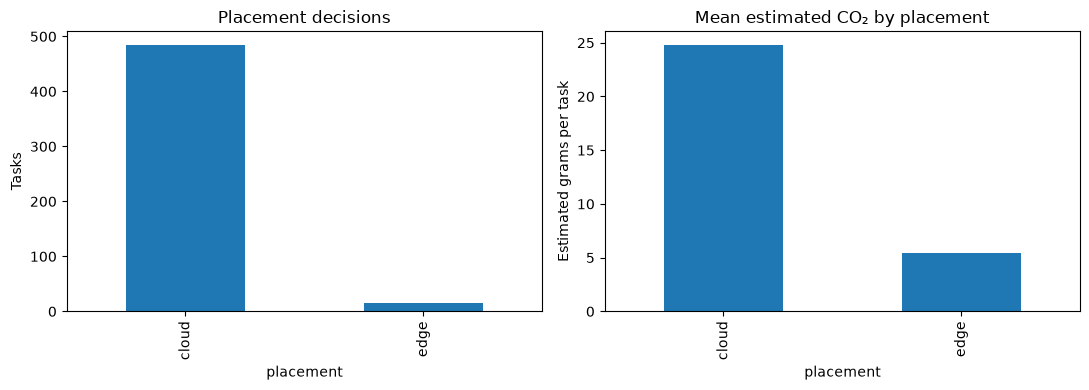

In [17]:
print("Tasks scheduled:", len(scheduler_results))
print("\nPlacement counts:")
display(scheduler_results["placement"].value_counts().to_frame("tasks"))

print("\nEstimated aggregate metrics (model-based estimates, not measured energy):")
display(pd.DataFrame([{
    "tasks": len(scheduler_results),
    "estimated_total_energy_kwh": scheduler_results["estimated_energy_kwh"].sum(),
    "estimated_total_co2_g": scheduler_results["estimated_co2_g"].sum(),
    "predicted_deadline_miss_rate": scheduler_results["deadline_miss_predicted"].astype(float).mean()
}]).round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
scheduler_results["placement"].value_counts().plot(kind="bar", ax=axes[0])
axes[0].set_title("Placement decisions")
axes[0].set_ylabel("Tasks")
scheduler_results.groupby("placement")["estimated_co2_g"].mean().plot(kind="bar", ax=axes[1])
axes[1].set_title("Mean estimated CO₂ by placement")
axes[1].set_ylabel("Estimated grams per task")
plt.tight_layout()
plt.show()

## 7A. Compare end-to-end scheduling results across selectable ML models

This is the experiment that mirrors the website dropdown: run the same held-out task sample and the same scheduling policy with each model that is actually available. Compare aggregate energy, CO₂ and predicted deadline misses. These are model-based estimates under the stated scheduler assumptions.

In [ ]:
model_simulation_rows = []
model_simulation_outputs = {}

for option in MODEL_OPTIONS:
    model_id = option["id"]
    result = run_simulation(
        model_name=model_id,
        tasks=test_duration,
        policy="proposed_weighted",
        max_tasks=500
    )
    model_simulation_outputs[model_id] = result
    model_simulation_rows.append({
        "model": model_id,
        "duration_model": result["duration_model"],
        "carbon_model": result["carbon_model"],
        "tasks_scheduled": result["tasks_scheduled"],
        "edge_tasks": result["placement_counts"].get("edge", 0),
        "cloud_tasks": result["placement_counts"].get("cloud", 0),
        "total_estimated_energy_kwh": result["total_estimated_energy_kwh"],
        "total_estimated_co2_g": result["total_estimated_co2_g"],
        "predicted_deadline_miss_rate": result["predicted_deadline_miss_rate"]
    })

model_simulation_comparison = pd.DataFrame(model_simulation_rows)
display(model_simulation_comparison.round(4))


## 8. Simple baseline comparison

This section compares the proposed scheduler's selected placement against two simple policies on the same held-out sample:
- **Always edge when feasible:** otherwise cloud.
- **Lowest current carbon:** choose the feasible candidate with lower carbon intensity, ignoring duration/energy weights.

This is an initial sanity-check comparison. For a research paper, implement the full baselines previously discussed: Round Robin, reactive threshold, CPU-aware, latency-aware, and carbon-aware without forecasting. Compare all policies on identical workloads and simulation seeds.

In [18]:
def evaluate_policy_for_task(row, predicted_duration, local_carbon, cloud_carbon, policy):
    deadline = float(row.get("delay_tolerance_sec", np.inf))
    cpu = float(row.get("cpu_demand", 0))
    gpu = float(row.get("gpu_demand", 0))
    feasible = []
    if gpu <= 0 or EDGE_GPU_CARDS > 0:
        feasible.append(("edge", estimate_power_watts(cpu, EDGE_IDLE_W, EDGE_FULL_W), local_carbon))
    if gpu <= 0 or CLOUD_GPU_CARDS > 0:
        feasible.append(("cloud", estimate_power_watts(cpu, CLOUD_IDLE_W, CLOUD_FULL_W), cloud_carbon))
    if not feasible:
        return None

    scored = {
        name: score_candidate(predicted_duration, power, carbon, deadline)
        for name, power, carbon in feasible
    }
    if policy == "proposed_weighted":
        chosen = min(scored, key=lambda name: scored[name]["score"])
    elif policy == "edge_first":
        chosen = "edge" if "edge" in scored else "cloud"
    elif policy == "lowest_carbon":
        chosen = min(feasible, key=lambda item: item[2])[0]
    else:
        raise ValueError("Unknown policy")

    return {"placement": chosen, **scored[chosen]}

comparison_records = []
for _, row in scheduler_test.head(500).iterrows():
    local_region = normalize_region_name(row.get("device_region", ""))
    cloud_region = normalize_region_name(row.get("cloud_region", "california"))
    local_carbon = carbon_forecast_lookup.get(local_region, float(row.get("carbon_intensity_local", 350.0)))
    cloud_carbon = carbon_forecast_lookup.get(cloud_region, float(row.get("carbon_intensity_cloud", 350.0)))
    local_carbon = float(local_carbon) if pd.notna(local_carbon) else float(row.get("carbon_intensity_local", 350.0))
    cloud_carbon = float(cloud_carbon) if pd.notna(cloud_carbon) else float(row.get("carbon_intensity_cloud", 350.0))

    for policy in ["proposed_weighted", "edge_first", "lowest_carbon"]:
        result = evaluate_policy_for_task(row, float(row["predicted_duration_sec"]), local_carbon, cloud_carbon, policy)
        if result:
            comparison_records.append({
                "policy": policy,
                "placement": result["placement"],
                "energy_kwh": result["energy_kwh"],
                "estimated_co2_g": result["estimated_co2_g"],
                "deadline_miss": result["deadline_miss"]
            })

comparison_df = pd.DataFrame(comparison_records)
comparison_summary = comparison_df.groupby("policy").agg(
    tasks=("placement", "size"),
    total_estimated_energy_kwh=("energy_kwh", "sum"),
    total_estimated_co2_g=("estimated_co2_g", "sum"),
    predicted_deadline_miss_rate=("deadline_miss", "mean")
).reset_index()
display(comparison_summary.round(4))

,policy,tasks,total_estimated_energy_kwh,total_estimated_co2_g,predicted_deadline_miss_rate
0,edge_first,500,67.9526,13620.4576,0.002
1,lowest_carbon,500,67.9526,12118.3070,0.002
2,proposed_weighted,500,67.9526,12118.3070,0.002


## 9. Save models and outputs

These artifacts can be used later by a Python inference service or exported into a Java/CloudSim integration workflow. The Java simulator should send task features to Python (for example through a REST API or a CSV handoff) and receive predicted duration/carbon values and a placement recommendation.

In [19]:
ARTIFACT_DIR = Path("ml_artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)

joblib.dump(duration_model, ARTIFACT_DIR / "duration_random_forest.joblib")
joblib.dump(carbon_model, ARTIFACT_DIR / "carbon_forecast_random_forest.joblib")

# Save additional fitted tabular models for reproducibility.
for model_name, fitted_model in duration_benchmark_fitted.items():
    safe_name = model_name.lower().replace(" ", "_")
    joblib.dump(fitted_model, ARTIFACT_DIR / f"duration_{safe_name}.joblib")
for model_name, fitted_model in carbon_benchmark_fitted.items():
    safe_name = model_name.lower().replace(" ", "_")
    joblib.dump(fitted_model, ARTIFACT_DIR / f"carbon_{safe_name}.joblib")
if lstm_model is not None:
    lstm_model.save(ARTIFACT_DIR / "carbon_lstm.keras")

duration_predictions.to_csv(ARTIFACT_DIR / "duration_test_predictions.csv", index=False)
carbon_predictions.to_csv(ARTIFACT_DIR / "carbon_test_predictions.csv", index=False)
scheduler_results.to_csv(ARTIFACT_DIR / "scheduler_demo_results.csv", index=False)
comparison_summary.to_csv(ARTIFACT_DIR / "scheduler_baseline_comparison.csv", index=False)
duration_comparison.to_csv(ARTIFACT_DIR / "duration_model_comparison.csv", index=False)
carbon_tree_comparison.to_csv(ARTIFACT_DIR / "carbon_tree_model_comparison.csv", index=False)
if not lstm_carbon_comparison.empty:
    lstm_carbon_comparison.to_csv(ARTIFACT_DIR / "carbon_lstm_comparison.csv", index=False)

print("Saved artifacts to:", ARTIFACT_DIR.resolve())
print(sorted(p.name for p in ARTIFACT_DIR.iterdir()))

# Portable bundle consumed by the website's FastAPI service.
inference_bundle = {
    "duration_models": DURATION_MODEL_REGISTRY,
    "carbon_models": CARBON_MODEL_REGISTRY,
    "lstm_model": None,  # Keras model is loaded from the separate .keras file by the API service.
    "lstm_model_path": str(ARTIFACT_DIR / "carbon_lstm.keras") if lstm_model is not None else None,
    "lstm_scalers": seq_scalers if "seq_scalers" in globals() else {},
    "lstm_window": LSTM_WINDOW,
    "duration_features": duration_features,
    "carbon_features": carbon_features,
    "carbon_numeric_features": carbon_features_num,
    "carbon_history": carbon_long[["carbon_timestamp_utc", "region", "carbon_intensity"]].copy(),
    "scheduler": {
        "edge_idle_w": EDGE_IDLE_W, "edge_full_w": EDGE_FULL_W,
        "cloud_idle_w": CLOUD_IDLE_W, "cloud_full_w": CLOUD_FULL_W,
        "edge_gpu_cards": EDGE_GPU_CARDS, "cloud_gpu_cards": CLOUD_GPU_CARDS,
        "cpu_demand_scale": CPU_DEMAND_SCALE,
        "weight_carbon": WEIGHT_CARBON, "weight_latency": WEIGHT_LATENCY,
        "weight_energy": WEIGHT_ENERGY, "deadline_penalty": DEADLINE_PENALTY
    },
    "model_options": MODEL_OPTIONS,
    "carbon_forecast_resolution_note": "one observed dataset time step"
}
joblib.dump(inference_bundle, ARTIFACT_DIR / "inference_bundle.joblib")
with open(ARTIFACT_DIR / "model_options.json", "w", encoding="utf-8") as f:
    json.dump(MODEL_OPTIONS, f, indent=2)
print("Website inference bundle saved:", (ARTIFACT_DIR / "inference_bundle.joblib").resolve())

if "model_simulation_comparison" in globals():
    model_simulation_comparison.to_csv(ARTIFACT_DIR / "model_simulation_comparison.csv", index=False)


Saved artifacts to: C:\Users\user\ml model gpt 2\ml_artifacts
['carbon_forecast_random_forest.joblib', 'carbon_test_predictions.csv', 'duration_random_forest.joblib', 'duration_test_predictions.csv', 'scheduler_baseline_comparison.csv', 'scheduler_demo_results.csv']


## 10. How to run a prediction for a new task

The task should contain the same feature columns used for training. This example uses a row from the dataset; replace it with a new task dictionary when integrating the scheduler.

### Website integration contract

After running the notebook, copy the generated `ml_artifacts/` folder and companion `ml_service.py` into your backend deployment. Start the API with:

```bash
pip install fastapi uvicorn pandas numpy scikit-learn joblib xgboost tensorflow
uvicorn ml_service:app --host 0.0.0.0 --port 8000
```

Endpoints:
- `GET /models` — returns only models actually present in the exported bundle.
- `POST /simulate` — accepts `model`, `policy`, `max_tasks`, and an optional `tasks` array.

Example request:

```json
{
  "model": "xgboost",
  "policy": "proposed_weighted",
  "max_tasks": 200
}
```

The API returns aggregate metrics plus per-task placement decisions. Do not expose the notebook itself to the browser or train models on every request; train offline and load the saved bundle once when the API starts.

In [20]:
example_task = df.iloc[[0]].copy()
example_duration = max(0.0, float(duration_model.predict(example_task[duration_features])[0]))

example_local_region = normalize_region_name(example_task.iloc[0].get("device_region", ""))
example_cloud_region = normalize_region_name(example_task.iloc[0].get("cloud_region", "california"))
example_local_carbon = carbon_forecast_lookup.get(
    example_local_region, float(example_task.iloc[0].get("carbon_intensity_local", 350.0))
)
example_cloud_carbon = carbon_forecast_lookup.get(
    example_cloud_region, float(example_task.iloc[0].get("carbon_intensity_cloud", 350.0))
)

example_decision = choose_placement(
    example_task.iloc[0],
    example_duration,
    float(example_local_carbon),
    float(example_cloud_carbon)
)

print("Predicted duration (sec):", round(example_duration, 2))
print("Forecast local carbon:", round(float(example_local_carbon), 2))
print("Forecast cloud carbon:", round(float(example_cloud_carbon), 2))
print("Placement:", example_decision["placement"])
display(pd.DataFrame(example_decision["candidates"]).T)

Predicted duration (sec): 158458.63
Forecast local carbon: 371.21
Forecast cloud carbon: 178.33
Placement: cloud


,duration_sec,power_w,energy_kwh,estimated_co2_g,deadline_miss,score
cloud,158458.631369,134.733333,5.930461,1057.60631,False,124.591934


## 11. Interpretation, limitations, and next research steps

### What this implementation contributes
- A reproducible ML pipeline using the supplied dataset.
- Duration prediction using task metadata.
- One-step-ahead regional carbon forecasting using past-only lag features.
- A forecast-aware, multi-objective placement prototype.
- Initial baselines and saved outputs.

### Limitations to document
- `observed_duration_sec` may reflect the source trace's execution environment; it is not guaranteed to equal execution time in our simulated edge/cloud infrastructure.
- Carbon values are forecast at the available observation interval. Longer horizons need separate evaluation.
- Energy is estimated from the supplied idle/full power values and a CPU-demand proxy; it is not a hardware measurement.
- Network latency and queue length are not directly measured in this workbook, so this prototype does not claim to optimize them precisely.
- The scheduler's weights and normalizers are hand-set parameters and should be tuned via sensitivity analysis.
- Random Forest is our first baseline. After validating this pipeline, compare XGBoost/HistGradientBoosting and a temporal model (for example LSTM) if enough time-series history is available.

### Recommended next experiment
Integrate the prediction function with CloudSim/EdgeCloudSim and compare:
1. Round Robin
2. Reactive CPU-threshold scheduling
3. CPU-aware scheduling
4. Carbon-aware scheduling without forecasting
5. **Forecast-driven carbon-aware scheduling (our proposed method)**

Use the same task trace and random seeds for every policy, then report mean latency, deadline violation rate, energy, CO₂ emissions, and utilization/overload statistics.

### Additional model-selection guidance
- Use **Random Forest / Extra Trees / HistGradientBoosting / XGBoost** for tabular task-duration and lag-feature carbon prediction.
- Use **LSTM** for carbon time-series sequences only when there is enough regular historical data. Compare it against persistence (last-value) and tree models.
- Consider **LightGBM or CatBoost** as further tree-boosting experiments if they are easy to install; they are optional, not required for the core study.
- Do not select the final model solely because it has the lowest score on the test set. Use a validation period inside the training period for model selection, then report the untouched test period once.
- For stronger forecasting research, add seasonal-naive baselines, multiple forecast horizons, rolling-origin evaluation, and uncertainty intervals.


### Website integration constraints
- The dropdown selects the carbon forecasting model and, for tree models, the corresponding task-duration model.
- LSTM is a carbon forecaster only in this implementation; duration prediction stays on Random Forest.
- The API bundle contains the historical carbon trace and trained models. The current service makes a one-step forecast from the latest available history; a time-evolving simulator should advance the history as simulation time advances.
- The notebook must be executed successfully with the dataset before the API bundle exists.
